<a href="https://colab.research.google.com/github/saketh-varma06/DL_ASSIGNMENTS/blob/main/DL_ASS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# --------------------------------------------------
# Load dataset
# --------------------------------------------------
df = pd.read_csv("/content/WineQT.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# --------------------------------------------------
# Features and target
# --------------------------------------------------
X = df.drop("quality", axis=1)
y = df["quality"]

# Convert wine quality into binary classification:
# quality >= 6 -> Good (1)
# quality < 6  -> Not Good (0)
y = (y >= 6).astype(np.float32)

print("\nClass distribution:")
print(y.value_counts())

# --------------------------------------------------
# Train/test split
# --------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# --------------------------------------------------
# Standardization
# --------------------------------------------------
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.values, dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.values, dtype=torch.float32
).reshape(-1, 1)

# DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X_train.shape[1])


Dataset shape: (1143, 13)
   fixed acidity  volatile acidity  citric acid  ...  alcohol  quality  Id
0            7.4              0.70         0.00  ...      9.4        5   0
1            7.8              0.88         0.00  ...      9.8        5   1
2            7.8              0.76         0.04  ...      9.8        5   2
3           11.2              0.28         0.56  ...      9.8        6   3
4            7.4              0.70         0.00  ...      9.4        5   4

[5 rows x 13 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-n

In [ ]:
class WineQualityNN(nn.Module):
    def __init__(self, input_size):
        super(WineQualityNN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create model
input_size = X_train.shape[1]

model = WineQualityNN(input_size)

print(model)


WineQualityNN(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [ ]:
# --------------------------------------------------
# Loss function and optimizer
# --------------------------------------------------
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# --------------------------------------------------
# Training
# --------------------------------------------------
epochs = 100

train_losses = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        # Forward pass
        outputs = model(X_batch)

        # Calculate loss
        loss = criterion(outputs, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {epoch_loss:.4f}"
        )


Epoch [10/100], Loss: 0.4665
Epoch [20/100], Loss: 0.4288
Epoch [30/100], Loss: 0.3938
Epoch [40/100], Loss: 0.3615
Epoch [50/100], Loss: 0.3002
Epoch [60/100], Loss: 0.2643
Epoch [70/100], Loss: 0.2189
Epoch [80/100], Loss: 0.1973
Epoch [90/100], Loss: 0.1657
Epoch [100/100], Loss: 0.1298


In [ ]:
# --------------------------------------------------
# Evaluation
# --------------------------------------------------
model.eval()

with torch.no_grad():
    logits = model(X_test_tensor)

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities >= 0.5).float()

# Convert tensors to NumPy
y_pred = predictions.numpy().flatten()
y_true = y_test_tensor.numpy().flatten()

# --------------------------------------------------
# Metrics
# --------------------------------------------------
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print("\nEvaluation Metrics")
print("------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Not Good", "Good"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)



Evaluation Metrics
------------------
Accuracy : 0.7511
Precision: 0.7724
Recall   : 0.7661
F1-score : 0.7692

Classification Report:
              precision    recall  f1-score   support

    Not Good       0.73      0.73      0.73       105
        Good       0.77      0.77      0.77       124

    accuracy                           0.75       229
   macro avg       0.75      0.75      0.75       229
weighted avg       0.75      0.75      0.75       229


Confusion Matrix:
[[77 28]
 [29 95]]


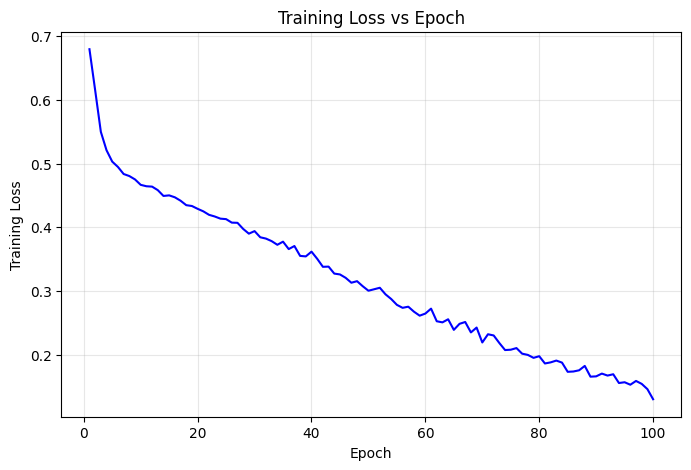

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    color="blue"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs Epoch")
plt.grid(alpha=0.3)

plt.show()


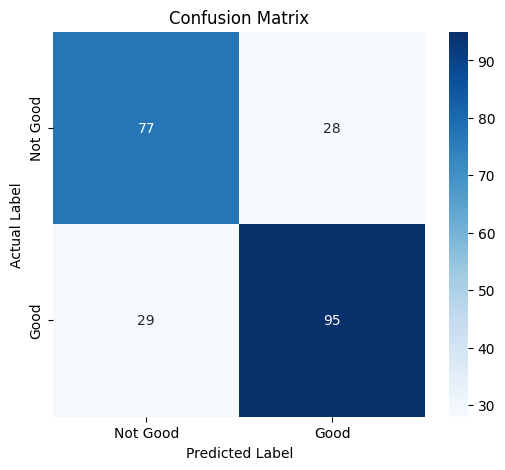

In [ ]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Good", "Good"],
    yticklabels=["Not Good", "Good"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()


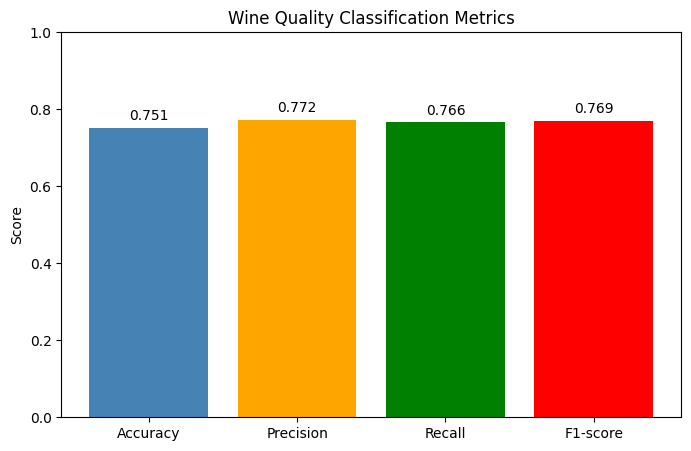

In [ ]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}

plt.figure(figsize=(8, 5))

plt.bar(
    metrics.keys(),
    metrics.values(),
    color=["steelblue", "orange", "green", "red"]
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Wine Quality Classification Metrics")

for i, value in enumerate(metrics.values()):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.show()
